# Case 1: 2025 trade-policy shocks and data center hardware supply

**What this notebook does.** It reads US imports of AI servers and of data center electrical gear from `core`, and shows where supply moved between origins and modes around the 2025 trade-policy shocks, and what that did to the transport emissions of delivering a tonne to the US. Servers were excluded from the reciprocal tariffs within days, while the electrical gear stayed exposed, so the gear is the comparison group.

**How it's organised.** Each section computes with the engine (`engine/`, pure functions) on data read by `analysis/src/shockt_analysis/core.py`, the only code that touches the database. The windows and the policy record come from the draft input files in `inputs/cases/tariffs_2025/`. The last section writes the derived evidence and proposes causal labels.

**Accounting, not attribution.** The numbers say what changed (DERIVED). Why it changed is the team's reading (INFERENCE), stated separately with its competing explanations. See the [Case 1 analysis plan](../../docs/plans/case-1-analysis.md).

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells. It reads; it never writes to the database.

## 1. Setup

The parameters below are the notebook's analytical choices. The product groups follow `config/hs_codes.yaml` and the exposure split follows the evidence record `ev_tariffs_section232_derivatives_transformers`.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
import yaml
from shockt_engine import (
    break_even_km,
    diversion_rate,
    load_leg_factors,
    select_factors,
    shares,
    window_summary,
)

from shockt_analysis import case1, core
from shockt_analysis.settings import REPO_ROOT, get_settings

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_float_precision(3)

CASE = "tariffs_2025"
CASE_DIR = REPO_ROOT / "inputs" / "cases" / CASE
NOTEBOOK = "analysis/case1/case1_tariffs_2025.ipynb"

PRODUCTS = {
    "servers": ["847150"],
    "gear": ["850421", "850422", "850423", "850433", "850434", "853720"],
}
GEAR_EXPOSURE = {
    "gear, reciprocal tariffs only": ["850421", "850422", "853720"],
    "gear, plus section 232 from Aug 2025": ["850423", "850433", "850434"],
}
NAMED_ORIGINS = ["TWN", "MEX", "THA", "VNM"]
GEAR_NAMED_ORIGINS = ["MEX", "KOR", "CHN", "TWN", "THA", "VNM"]
COMPARISON_ORIGINS = ["TWN", "MEX", "KOR", "CHN", "THA", "VNM"]

windows = case1.load_windows(CASE_DIR / "shock_windows.yaml")
WINDOW_COLORS = {"baseline": "#d9e5d6", "anticipation": "#f3dfb6", "response": "#f0c7c0"}
[(w.name, w.first, w.last) for w in windows]

[('baseline', datetime.date(2024, 1, 1), datetime.date(2025, 1, 1)),
 ('anticipation', datetime.date(2025, 2, 1), datetime.date(2025, 4, 1)),
 ('response', datetime.date(2025, 5, 1), datetime.date(2025, 12, 1))]

Read everything the notebook needs in one connection, and choose each mode's emission factor. `select_factors` fails if `engine/config/leg_factors.yaml` names no factor, or several, for a mode.

In [2]:
all_codes = PRODUCTS["servers"] + PRODUCTS["gear"]
with core.connect(get_settings()) as conn:
    supply = core.supply(conn, all_codes)
    node_weights = core.node_weights(conn, all_codes)
    observed_sea = core.observed_sea(conn)
    distances = {seed: core.distances(conn, seed) for seed in ("sea", "air", "road", "rail")}
    crossing_plants = core.crossing_plants(conn)
    factor_rows = core.factors(conn)
    loads = core.current_loads(
        conn,
        [
            "census_hs",
            "census_porths",
            "census_statehs",
            "bts_transborder",
            "climatetrace_voyages",
            "bts_t100_segments",
            "uk_ghg_conversion_factors",
            "epa_ghg_transport_factors",
            "epa_ghg_gwp",
            "denue_establishments",
            "ourairports_airports",
            "geonames_cities",
        ],
    )

leg_factors = select_factors(factor_rows, load_leg_factors())
context = case1.LaneContext(
    weights=node_weights,
    observed_sea=observed_sea,
    distances=distances,
    factors={mode: f.wtw_kg_co2e_per_tkm for mode, f in leg_factors.items()},
    crossing_plants=crossing_plants,
)
pl.DataFrame(
    [
        {
            "mode": mode,
            "factor": f.variant,
            "source": f.source,
            "kg CO2e per tonne-km": f.wtw_kg_co2e_per_tkm,
        }
        for mode, f in leg_factors.items()
    ]
)

mode,factor,source,kg CO2e per tonne-km
str,str,str,f64
"""ocean""","""Cargo ship / Container ship / …","""uk_desnz""",0.020
"""air""","""Freight flights / Internationa…","""uk_desnz""",1.035
"""truck""","""Medium- and Heavy-Duty Truck""","""epa_hub""",0.159
"""rail""","""Rail""","""epa_hub""",0.018


In [3]:
print(f"Supply rows: {supply.height:,}; months {supply['month'].min()} to {supply['month'].max()}")
loads

Supply rows: 5,563; months 2022-01-01 to 2026-08-01


dataset,partitions,latest_load,code_versions
str,i64,str,str
"""bts_t100_segments""",5,"""2026-10-13 01:07:44.08102+00""","""d3cc89b-dirty"""
"""bts_transborder""",56,"""2026-10-09 20:16:51.61352+00""","""a9aec6f-dirty"""
"""census_hs""",392,"""2026-10-12 22:36:31.151388+00""","""89ea1ba, ae62e94-dirty"""
"""census_porths""",392,"""2026-10-12 22:32:46.809638+00""","""89ea1ba, ae62e94-dirty"""
"""census_statehs""",392,"""2026-10-12 22:33:12.330056+00""","""89ea1ba, ae62e94-dirty"""
"""climatetrace_voyages""",5,"""2026-10-12 22:52:15.201059+00""","""20b5845"""
"""denue_establishments""",1,"""2026-10-12 23:08:01.487724+00""","""e71dd40"""
"""epa_ghg_gwp""",1,"""2026-10-12 22:52:51.50207+00""","""20b5845"""
"""epa_ghg_transport_factors""",1,"""2026-10-12 22:52:48.687086+00""","""20b5845"""


## 2. The policy record

The FACT records in `evidence.yaml`, each checked against its official source. Servers (heading 8471) were excluded from the reciprocal tariffs within nine days; the electrical gear wasn't.

In [4]:
evidence = yaml.safe_load((CASE_DIR / "evidence.yaml").read_text())
timeline = pl.DataFrame(
    [
        {
            "date": str(r["source"].get("signed") or r["source"].get("published")),
            "id": r["id"],
            "citation": r["source"].get("citation", r["source"]["issuer"]),
            "claim": " ".join(r["claim"].split()),
        }
        for r in evidence["records"]
    ]
).sort("date")
with pl.Config(fmt_str_lengths=200):
    display(timeline)

date,id,citation,claim
str,str,str,str
"""2025-02-01""","""ev_tariffs_eo14194_mexico_duty""","""90 FR 9117""","""Executive Order 14194 imposed an additional 25% ad valorem duty on products of Mexico, originally from February 4, 2025."""
"""2025-02-03""","""ev_tariffs_eo14198_mexico_pause""","""90 FR 9185""","""Executive Order 14198 paused the 25% duty on products of Mexico until 12:01 a.m. eastern time on March 4, 2025."""
"""2025-03-06""","""ev_tariffs_cbp_mexico_implementation""","""90 FR 11429""","""CBP implemented the additional duty on products of Mexico for goods entered on or after 12:01 a.m. EST on March 4, 2025."""
"""2025-03-06""","""ev_tariffs_eo14232_usmca_exemption""","""90 FR 11787""","""Executive Order 14232 exempted from the duty on products of Mexico the articles that enter free of duty as goods of Mexico under general note 11 of the HTSUS (USMCA treatment), for goods entered on or…"
"""2025-04-02""","""ev_tariffs_eo14257_reciprocal_tariff""","""90 FR 15041""","""Executive Order 14257 imposed an additional 10% ad valorem duty on imports from 12:01 a.m. EDT on April 5, 2025, and higher country-specific rates from 12:01 a.m. EDT on April 9, 2025."""
"""2025-04-02""","""ev_tariffs_eo14257_annex2_omits_gear""","""90 FR 15041""","""Annex II of Executive Order 14257, the products not subject to the reciprocal tariffs, lists no subheading of 8504 or 8537; its chapter 85 entries are semiconductors (8541 and 8542)."""
"""2025-04-11""","""ev_tariffs_cbp_8471_exclusion""","""U.S. Customs and Border Protection""","""CBP excluded HTSUS heading 8471, which includes servers (8471.50), from the reciprocal tariffs for goods entered on or after 12:01 a.m. EDT on April 5, 2025, the date the 10% duty began."""
"""2025-04-11""","""ev_tariffs_cbp_exclusion_omits_gear""","""U.S. Customs and Border Protection""","""The CBP exclusion list for the reciprocal tariffs names no subheading of heading 8504 (transformers) or 8537 (switchgear), so the case's electrical gear stayed subject to them."""
"""2025-04-16""","""ev_tariffs_section232_semiconductors""","""90 FR 15950""","""On April 1, 2025, the Secretary of Commerce initiated a section 232 investigation of imports of semiconductors, semiconductor manufacturing equipment and their derivative products."""


## 3. Monthly supply

Tonnes of servers delivered to the US each month, by origin, with the windows shaded. Air and vessel weights are reported by Census; truck and rail from Mexico are estimated from value (`fct_mexico_overland_monthly`), so their range is shown separately in Section 6.

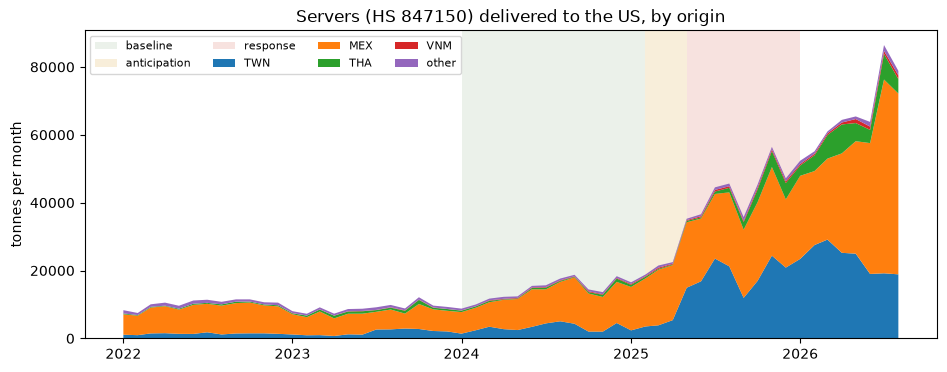

In [6]:
def shade_windows(ax):
    for w in windows:
        ax.axvspan(
            w.first,
            date(w.last.year + (w.last.month == 12), w.last.month % 12 + 1, 1),
            color=WINDOW_COLORS[w.name],
            alpha=0.5,
            lw=0,
            label=w.name,
        )


def plot_by_origin(codes, named, title):
    monthly = case1.monthly_supply(supply, codes, named)
    pivot = (
        monthly.group_by("month", "origin_group")
        .agg(pl.col("weight_t").sum())
        .pivot(on="origin_group", index="month", values="weight_t")
        .sort("month")
        .fill_null(0)
    )
    order = [o for o in named + [case1.OTHER] if o in pivot.columns]
    fig, ax = plt.subplots(figsize=(11, 4))
    shade_windows(ax)
    ax.stackplot(pivot["month"].to_list(), *[pivot[o].to_list() for o in order], labels=order)
    ax.set_title(title)
    ax.set_ylabel("tonnes per month")
    ax.legend(loc="upper left", ncols=4, fontsize=8)
    plt.show()
    return monthly


servers_monthly = plot_by_origin(
    PRODUCTS["servers"], NAMED_ORIGINS, "Servers (HS 847150) delivered to the US, by origin"
)

Within each origin, the mode: Taiwan already ships almost all of its servers by air, so a shift toward air can't show for Taiwan; Mexico's are almost all overland.

In [7]:
mode_shares = case1.window_shares(servers_monthly, windows, ["origin_group", "mode"])
by_origin = mode_shares.group_by("window", "origin_group").agg(
    pl.col("weight_t").sum().alias("origin_t")
)
(
    mode_shares.join(by_origin, on=["window", "origin_group"])
    .with_columns((pl.col("weight_t") / pl.col("origin_t")).alias("share_within_origin"))
    .pivot(on="window", index=["origin_group", "mode"], values="share_within_origin")
    .select("origin_group", "mode", *[w.name for w in windows])
    .sort("origin_group", "mode")
)

origin_group,mode,baseline,anticipation,response
str,str,f64,f64,f64
"""MEX""","""air""",0.005,0.003,0.008
"""MEX""","""rail""",0.011,0.026,0.016
"""MEX""","""truck""",0.983,0.970,0.976
"""MEX""","""vessel""",0.001,0.000,0.000
"""THA""","""air""",0.874,0.887,0.981
"""THA""","""vessel""",0.126,0.113,0.019
"""TWN""","""air""",0.953,0.951,0.986
"""TWN""","""vessel""",0.047,0.049,0.014
"""VNM""","""air""",0.541,0.832,0.656


## 4. Origin shares and diversion rates

Each origin's share of server tonnage per window, and its change from the baseline. A diversion rate is the fraction of one category's baseline tonnage that moved to another: r = (s_to,response − s_to,baseline) / s_from,baseline (the proposal's definition). It is computed for each month of a window against the baseline, and the window keeps the weighted mean, the lowest and the highest.

In [9]:
origin_shares = case1.window_shares(servers_monthly, windows, ["origin_group"])
shares_table = origin_shares.pivot(on="window", index="origin_group", values="share").select(
    "origin_group", *[w.name for w in windows]
)
changes = case1.share_changes(origin_shares, "baseline", "response", "origin_group")
shares_table.with_columns(
    pl.col("origin_group")
    .replace_strict(changes, default=None)
    .alias("change_baseline_to_response")
)

origin_group,baseline,anticipation,response,change_baseline_to_response
str,f64,f64,f64,f64
"""MEX""",0.704,0.745,0.485,-0.219
"""THA""",0.030,0.015,0.053,0.023
"""TWN""",0.218,0.203,0.434,0.216
"""VNM""",0.011,0.012,0.010,-0.001
"""other""",0.036,0.025,0.018,-0.018


In [10]:
def monthly_origin_shares(monthly):
    totals = monthly.group_by("month", "origin_group").agg(pl.col("weight_t").sum())
    return {
        m: shares(
            dict(zip(part["origin_group"].to_list(), part["weight_t"].to_list(), strict=True))
        )
        for (m,), part in totals.group_by("month")
    }


def diversion_by_window(monthly, source, target):
    base = origin_shares.filter(pl.col("window") == "baseline")
    baseline = dict(zip(base["origin_group"].to_list(), base["share"].to_list(), strict=True))
    by_month = monthly_origin_shares(monthly)
    rates = {
        m: diversion_rate(baseline[source], baseline[target], s.get(target, 0.0))
        for m, s in by_month.items()
    }
    tonnes = dict(monthly.group_by("month").agg(pl.col("weight_t").sum()).iter_rows())
    later = [w for w in windows if w.name != "baseline"]
    return {name: s for name, s in window_summary(rates, later, tonnes).items()}


mex_to_twn = diversion_by_window(servers_monthly, "MEX", "TWN")
pl.DataFrame(
    [
        {"window": k, "mean": v.mean, "low": v.low, "high": v.high, "months": v.months}
        for k, v in mex_to_twn.items()
    ]
)

window,mean,low,high,months
str,f64,f64,f64,i64
"""anticipation""",-0.022,-0.055,0.030,3
"""response""",0.307,0.164,0.440,8


Read the table above as: in the response window, a share of Mexico's baseline server tonnage equal to `mean` moved to Taiwan, ranging from `low` to `high` across months. The rate is net, as the proposal notes: it records the change in shares, not which shipments moved.

## 5. Delivery emissions per tonne, by lane

A lane is an origin and a delivery mode. Its emissions per tonne are the sum over its legs of distance × factor, with each leg's distance averaged over the airports, ports, crossings and states the lane uses, weighted by their tonnage in the window. Sea distances are observed from the origin's voyages where they exist, and `searoute` open-route distances otherwise. `covered_share` is the share of a leg's weight whose node pairs have a distance.

In [11]:
server_lanes, server_legs = case1.lane_intensities(supply, PRODUCTS["servers"], windows, context)
(
    server_lanes.filter(pl.col("iso3").is_in(NAMED_ORIGINS))
    .pivot(on="window", index=["iso3", "mode"], values="kg_co2e_per_t")
    .select("iso3", "mode", *[w.name for w in windows])
    .sort("iso3", "mode")
)

iso3,mode,baseline,anticipation,response
str,str,f64,f64,f64
"""MEX""","""air""",2858.838,2622.410,2674.662
"""MEX""","""rail""",52.967,37.770,41.012
"""MEX""","""truck""",214.723,208.127,204.292
"""MEX""","""vessel""",263.149,216.850,200.424
"""THA""","""air""",14932.103,14804.238,14842.761
"""THA""","""vessel""",522.009,418.342,553.530
"""TWN""","""air""",12214.718,12198.406,11987.581
"""TWN""","""vessel""",410.618,423.789,381.837
"""VNM""","""air""",12895.221,13051.218,13342.220


In [10]:
print("Lanes with tonnage but no measurable legs (left out of the mix):")
display(server_lanes.filter(pl.col("kg_co2e_per_t").is_null()))
(
    server_legs.filter(
        (pl.col("window") == "response")
        & pl.struct("iso3", "mode").is_in(
            [
                {"iso3": "TWN", "mode": "air"},
                {"iso3": "MEX", "mode": "truck"},
                {"iso3": "MEX", "mode": "rail"},
            ]
        )
    ).select(
        "iso3",
        "mode",
        "leg",
        "factor_mode",
        "km",
        "kg_co2e_per_tkm",
        "kg_co2e_per_t",
        "covered_share",
    )
)

Lanes with tonnage but no measurable legs (left out of the mix):


window,iso3,mode,weight_t,kg_co2e_per_t,missing
str,str,str,f64,f64,str
"""baseline""","""BRN""","""air""",0.007,null,"""a leg needs positive weights a…"
"""baseline""","""LKA""","""air""",2.876,null,"""a leg needs positive weights a…"
"""response""","""IRQ""","""air""",0.029,null,"""a leg needs positive weights a…"
"""response""","""LKA""","""air""",0.005,null,"""a leg needs positive weights a…"


iso3,mode,leg,factor_mode,km,kg_co2e_per_tkm,kg_co2e_per_t,covered_share
str,str,str,str,f64,f64,f64,f64
"""MEX""","""rail""","""plant → crossing""","""truck""",124.124,0.159,19.676,1.000
"""MEX""","""rail""","""crossing → state""","""rail""",1191.480,0.018,21.335,1.000
"""MEX""","""truck""","""plant → crossing""","""truck""",84.926,0.159,13.463,1.000
"""MEX""","""truck""","""crossing → state""","""truck""",1203.812,0.159,190.829,1.000
"""TWN""","""air""","""airport → gateway""","""air""",11265.789,1.035,11655.022,1.000
"""TWN""","""air""","""gateway → state""","""truck""",2097.890,0.159,332.559,0.995


## 6. The supply mix

The emissions per tonne of all US server supply in a month: each origin lane's share of the month's tonnes × the lane's intensity in that window. This is the case's headline, and it doesn't move with total volume, only with where and how supply arrives. The range across months is the window's low and high; Mexico's overland tonnage range is shown as a second, separate range.

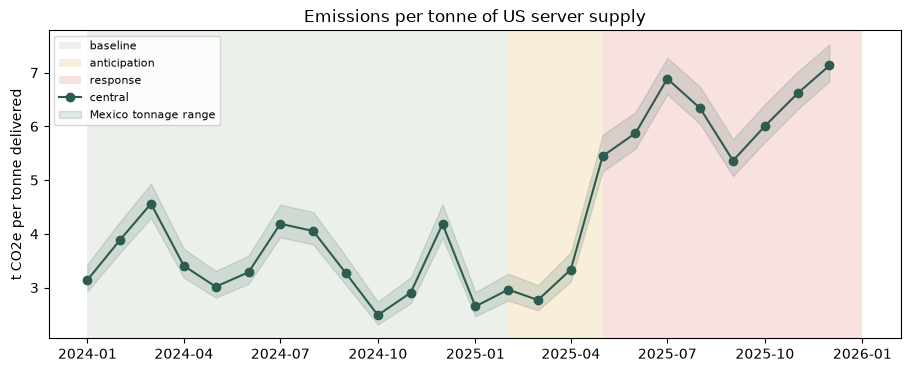

window,mean_kg_per_t,low,high,months,change_from_baseline
str,f64,f64,f64,i64,f64
"""baseline""",3471.301,2487.940,4561.944,13,0.000
"""anticipation""",3030.488,2768.920,3336.430,3,-0.127
"""response""",6277.708,5361.834,7132.938,8,0.808


In [11]:
mix = {
    estimate: case1.mix_by_month(supply, PRODUCTS["servers"], windows, server_lanes, tonnes=column)
    for estimate, column in [
        ("central", "weight_t"),
        ("mexico low", "weight_t_low"),
        ("mexico high", "weight_t_high"),
    ]
}
fig, ax = plt.subplots(figsize=(11, 4))
shade_windows(ax)
central = mix["central"]
ax.plot(
    central["month"].to_list(),
    (central["kg_co2e_per_t"] / 1000).to_list(),
    marker="o",
    color="#2d5b4f",
    label="central",
)
ax.fill_between(
    central["month"].to_list(),
    (mix["mexico high"]["kg_co2e_per_t"] / 1000).to_list(),
    (mix["mexico low"]["kg_co2e_per_t"] / 1000).to_list(),
    color="#2d5b4f",
    alpha=0.15,
    label="Mexico tonnage range",
)
ax.set_ylabel("t CO2e per tonne delivered")
ax.set_title("Emissions per tonne of US server supply")
ax.legend(loc="upper left", fontsize=8)
plt.show()

values = dict(zip(central["month"].to_list(), central["kg_co2e_per_t"].to_list(), strict=True))
weights = dict(zip(central["month"].to_list(), central["t"].to_list(), strict=True))
mix_summary = window_summary(values, windows, weights)
mix_table = pl.DataFrame(
    [
        {
            "window": name,
            "mean_kg_per_t": s.mean,
            "low": s.low,
            "high": s.high,
            "months": s.months,
            "change_from_baseline": s.mean / mix_summary["baseline"].mean - 1,
        }
        for name, s in mix_summary.items()
    ]
)
mix_table

## 7. The missing leg into Mexico

The Mexico route's advantage over Taiwan by air is measured for the delivery into the US only; the components flown or shipped into Mexico aren't in the data. The break-even is how far a tonne of components would have to travel, by each mode, to cancel that advantage. It assumes about one tonne of components per tonne of servers.

In [12]:
response_lanes = server_lanes.filter(pl.col("window") == "response")


def lane_value(iso3, mode):
    return response_lanes.filter((pl.col("iso3") == iso3) & (pl.col("mode") == mode))[
        "kg_co2e_per_t"
    ].item()


advantage = lane_value("TWN", "air") - lane_value("MEX", "truck")
break_even = {
    mode: break_even_km(advantage, leg_factors[mode].wtw_kg_co2e_per_tkm)
    for mode in ("ocean", "air")
}
print(
    f"Mexico by truck is {advantage:,.0f} kg CO2e per tonne below Taiwan by air (response window)."
)
for mode, km in break_even.items():
    print(f"  Components by {mode} cancel it after {km:,.0f} km per tonne.")

Mexico by truck is 11,783 kg CO2e per tonne below Taiwan by air (response window).
  Components by ocean cancel it after 596,019 km per tonne.
  Components by air cancel it after 11,390 km per tonne.


## 8. The comparison: exempt servers against exposed gear

The same origin shares for the electrical gear, which stayed subject to the reciprocal tariffs, three codes of it also to the steel and aluminum duty from August 18, 2025. If the exposed gear's origins moved while the exempt servers' didn't, that points to the tariffs; if both moved alike, or only the servers, demand is the likelier driver. The comparison is of changes in share, not levels, with the same origins named for every group.

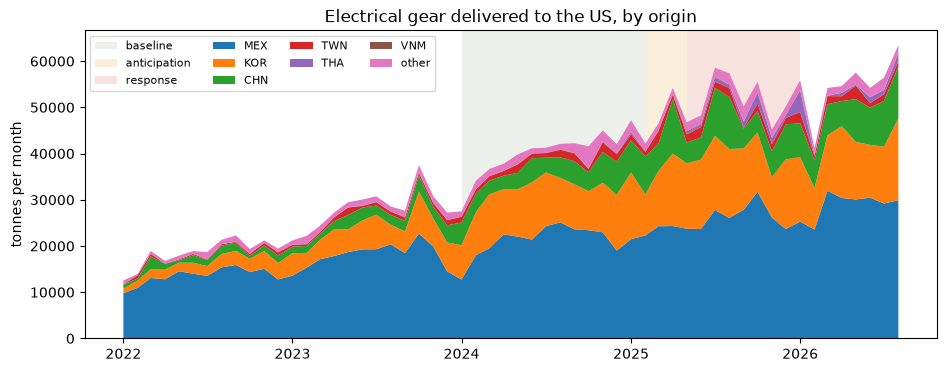

origin,servers,gear,"gear, reciprocal tariffs only","gear, plus section 232 from Aug 2025"
str,f64,f64,f64,f64
"""CHN""",-0.014,0.011,0.021,-0.009
"""KOR""",-0.000,0.002,-0.017,0.035
"""MEX""",-0.219,-0.021,-0.017,-0.027
"""THA""",0.023,0.018,0.023,0.008
"""TWN""",0.216,-0.003,-0.017,0.023
"""VNM""",-0.001,0.001,0.001,0.000
"""other""",-0.005,-0.007,0.006,-0.029


In [12]:
gear_monthly = plot_by_origin(
    PRODUCTS["gear"], GEAR_NAMED_ORIGINS, "Electrical gear delivered to the US, by origin"
)
groups = {"servers": PRODUCTS["servers"], "gear": PRODUCTS["gear"], **GEAR_EXPOSURE}
comparison_rows = []
for group, codes in groups.items():
    ws = case1.window_shares(
        case1.monthly_supply(supply, codes, COMPARISON_ORIGINS), windows, ["origin_group"]
    )
    for window in ("anticipation", "response"):
        for origin, change in case1.share_changes(ws, "baseline", window, "origin_group").items():
            comparison_rows.append(
                {"group": group, "window": window, "origin": origin, "share_change": change}
            )
comparison = pl.DataFrame(comparison_rows)
(
    comparison.filter(pl.col("window") == "response")
    .pivot(on="group", index="origin", values="share_change")
    .sort("origin")
)

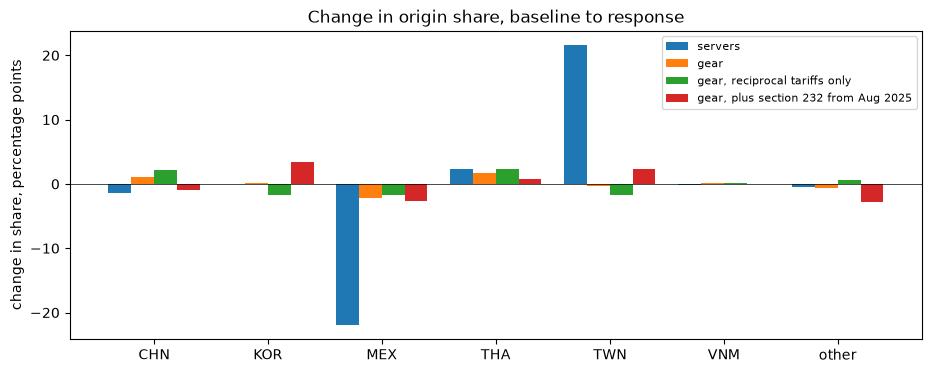

In [14]:
fig, ax = plt.subplots(figsize=(11, 4))
response = comparison.filter(pl.col("window") == "response")
origins_order = sorted(response["origin"].unique().to_list())
width = 0.8 / len(groups)
for i, group in enumerate(groups):
    part = dict(
        response.filter(pl.col("group") == group).select("origin", "share_change").iter_rows()
    )
    ax.bar(
        [j + i * width for j in range(len(origins_order))],
        [part.get(o, 0.0) * 100 for o in origins_order],
        width,
        label=group,
    )
ax.set_xticks([j + width * (len(groups) - 1) / 2 for j in range(len(origins_order))], origins_order)
ax.axhline(0, color="black", lw=0.5)
ax.set_ylabel("change in share, percentage points")
ax.set_title("Change in origin share, baseline to response")
ax.legend(fontsize=8)
plt.show()

## 9. Findings

The DERIVED statements below are computed from the cells above, so they change with the data. The INFERENCE that follows is the team's reading and must cite them.

In [15]:
servers_change = dict(
    comparison.filter((pl.col("group") == "servers") & (pl.col("window") == "response"))
    .select("origin", "share_change")
    .iter_rows()
)
gear_change = dict(
    comparison.filter((pl.col("group") == "gear") & (pl.col("window") == "response"))
    .select("origin", "share_change")
    .iter_rows()
)
largest_gear = max(gear_change.items(), key=lambda kv: abs(kv[1]))
base, resp = mix_summary["baseline"], mix_summary["response"]
twn, mex = servers_change["TWN"] * 100, servers_change["MEX"] * 100
twn_air, mex_truck = lane_value("TWN", "air") / 1000, lane_value("MEX", "truck") / 1000
findings = [
    f"Taiwan's share of US server tonnage changed by {twn:+.1f} percentage points and Mexico's "
    f"by {mex:+.1f} from the baseline to the response window.",
    f"The emissions per tonne of US server supply averaged {base.mean / 1000:.2f} t CO2e in the "
    f"baseline and {resp.mean / 1000:.2f} t in the response window "
    f"({resp.mean / base.mean - 1:+.0%}); monthly range "
    f"{resp.low / 1000:.2f}-{resp.high / 1000:.2f} t.",
    f"Taiwan by air emits {twn_air:.1f} t CO2e per tonne delivered; Mexico by truck "
    f"{mex_truck:.2f} t (delivery into the US only).",
    f"Components flown into Mexico would cancel that advantage after about "
    f"{break_even['air']:,.0f} km per tonne; by sea, only after {break_even['ocean']:,.0f} km.",
    f"For the exposed electrical gear, the largest change in origin share was {largest_gear[0]}'s, "
    f"{largest_gear[1] * 100:+.1f} percentage points.",
]
for f in findings:
    print("-", f)

- Taiwan's share of US server tonnage changed by +21.6 percentage points and Mexico's by -21.9 from the baseline to the response window.
- The emissions per tonne of US server supply averaged 3.47 t CO2e in the baseline and 6.28 t in the response window (+81%); monthly range 5.36-7.13 t.
- Taiwan by air emits 12.0 t CO2e per tonne delivered; Mexico by truck 0.20 t (delivery into the US only).
- Components flown into Mexico would cancel that advantage after about 11,390 km per tonne; by sea, only after 596,019 km.
- For the exposed electrical gear, the largest change in origin share was MEX's, -2.1 percentage points.


**What the data suggests (INFERENCE, for the team to review).** Servers were exempt from the reciprocal tariffs, yet their supply shifted strongly toward Taiwan by air after the exemption, while the exposed gear's origins barely moved. That pattern doesn't fit a tariff response; growth in AI server demand, met by Taiwan's air-freighted output, is the likelier driver. The shift raised the emissions per tonne of US server supply, because Taiwan's air lane emits many times more per tonne than Mexico's truck lane (Section 5). A gear share that rose in the anticipation window and fell back after (China's, on first look) would be consistent with front-loading ahead of the tariffs, but the evidence file has no China-specific record yet.

**What it can't say.** Monthly data can't separate the tariff announcements from demand or capacity changes in the same months; components into Mexico aren't measured; and a lane's legs assume its airports, ports and destinations are used independently of each other.

## 10. Write the derived evidence and propose causal labels

`evidence_derived.yaml` is regenerated on every run; don't edit it by hand. `causal_labels.proposed.yaml` is a starting point: the analyst copies what holds into `causal_labels.yaml`, with the Shock-T status and evidence they agree.

In [16]:
provenance = {
    "notebook": NOTEBOOK,
    "git_commit": case1.git_commit(),
    "windows_file": "inputs/cases/tariffs_2025/shock_windows.yaml",
    "run_at": date.today().isoformat(),
    "data": loads.to_dicts(),
}
derived = [
    {
        "id": "ev_derived_server_origin_shares",
        "basis": "DERIVED",
        "claim": findings[0],
        "metric": "shockt_engine.share_change",
        "parameters": {
            "hs6": PRODUCTS["servers"],
            "windows": ["baseline", "response"],
            "origins": NAMED_ORIGINS,
        },
        "values": {k: round(v, 4) for k, v in servers_change.items()},
    },
    {
        "id": "ev_derived_server_mix_intensity",
        "basis": "DERIVED",
        "claim": findings[1],
        "metric": "shockt_engine.mix_intensity",
        "parameters": {"hs6": PRODUCTS["servers"], "leg_factors": "engine/config/leg_factors.yaml"},
        "values": {
            r["window"]: {k: round(r[k], 1) for k in ("mean_kg_per_t", "low", "high")}
            for r in mix_table.to_dicts()
        },
    },
    {
        "id": "ev_derived_server_lane_intensities",
        "basis": "DERIVED",
        "claim": findings[2],
        "metric": "shockt_engine.lane_legs",
        "parameters": {"hs6": PRODUCTS["servers"], "window": "response"},
        "values": {
            f"{r['iso3']}_{r['mode']}": round(r["kg_co2e_per_t"], 1)
            for r in response_lanes.drop_nulls("kg_co2e_per_t")
            .filter(pl.col("iso3").is_in(NAMED_ORIGINS))
            .to_dicts()
        },
    },
    {
        "id": "ev_derived_mexico_component_break_even",
        "basis": "DERIVED",
        "claim": findings[3],
        "metric": "shockt_engine.break_even_km",
        "parameters": {
            "advantage": "TWN air minus MEX truck, response window",
            "component_tonnes_per_tonne": 1,
        },
        "values": {mode: round(km) for mode, km in break_even.items()},
    },
    {
        "id": "ev_derived_gear_origin_shares",
        "basis": "DERIVED",
        "claim": findings[4],
        "metric": "shockt_engine.share_change",
        "parameters": {
            "hs6": PRODUCTS["gear"],
            "windows": ["baseline", "response"],
            "origins": GEAR_NAMED_ORIGINS,
        },
        "values": {k: round(v, 4) for k, v in gear_change.items()},
    },
]
case1.write_derived(CASE_DIR / "evidence_derived.yaml", CASE, derived, provenance)

proposed = {
    "case": CASE,
    "status": "proposed",
    "labels": [
        {
            "lane": "TWN-US",
            "observed_response": (
                "Taiwan's share of server tonnage rose after the server exclusion, "
                "almost all by air."
            ),
            "proposed_status": "TEMPORAL_ALIGNMENT",
            "competing_explanations": [
                "Growth in AI server demand",
                "Taiwan capacity and product mix shifting toward AI racks",
            ],
            "evidence": [
                "ev_tariffs_cbp_8471_exclusion",
                "ev_derived_server_origin_shares",
                "ev_derived_gear_origin_shares",
            ],
            "note": (
                "Servers were exempt from the reciprocal tariffs, so the alignment is in "
                "time only; "
                "the exposed gear didn't shift alike."
            ),
        },
        {
            "lane": "MEX-US",
            "observed_response": (
                "Mexico's share of server tonnage fell while its tonnage kept growing."
            ),
            "proposed_status": "TEMPORAL_ALIGNMENT",
            "competing_explanations": [
                "Taiwan's growth outpacing Mexico's",
                "USMCA treatment of Mexican-assembled servers not established",
            ],
            "evidence": ["ev_tariffs_eo14232_usmca_exemption", "ev_derived_server_origin_shares"],
        },
    ],
}
(CASE_DIR / "causal_labels.proposed.yaml").write_text(
    "# Proposed by the Case 1 notebook; copy what holds into causal_labels.yaml.\n"
    + yaml.safe_dump(proposed, sort_keys=False, allow_unicode=True, width=100)
)
print(
    "Wrote",
    (CASE_DIR / "evidence_derived.yaml").relative_to(REPO_ROOT),
    "and",
    (CASE_DIR / "causal_labels.proposed.yaml").relative_to(REPO_ROOT),
)

Wrote inputs/cases/tariffs_2025/evidence_derived.yaml and inputs/cases/tariffs_2025/causal_labels.proposed.yaml
